## 清洗合并数据与训练
把所有的电能需求数据和天气数据，还有刚才做完的时间序列特征，合并在一起，组成建模数据。然后用XGBoost训练。这里只用地区为capital的数据训练和预测，与ISO的预测数据对比（同为capital地区）。需要注意的是我们用的是实测气温，NYISO 用的只能是天气预报。所以即使结果更好，也带着这个优势。

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
%matplotlib inline

### 1. 数据清洗与合并

导入2021-2025的数据

In [3]:
loads_captial = pd.read_csv('../data/nyiso/all/capital.csv')
weather_captial = pd.read_csv('../data/wunderground/kalb_all.csv')

In [4]:
print(loads_captial.columns)
print(weather_captial.columns)

Index(['timestamp', 'name', 'ptid', 'load'], dtype='str')
Index(['timeest', 'temperaturef', 'dewpointf', 'humidity',
       'sealevelpressurein', 'visibilitymph', 'winddirdegrees', 'windspeedkmh',
       'gustspeedkmh', 'precipitationmm', 'conditions', 'dateutc'],
      dtype='str')


In [5]:
# 格式化时间列
weather_captial['timestamp'] = pd.to_datetime(weather_captial.timeest)
loads_captial.timestamp = pd.to_datetime(loads_captial.timestamp)

# 去掉气象要素缺失的记录，虽然样本缺失对 XGBoost 没有影响，它能直接处理缺失值，但是去掉的话最近邻会匹配到最近的一条有效记录，而不是一条空记录。
weather_captial = weather_captial.dropna(subset=['temperaturef', 'dewpointf', 'humidity', 'sealevelpressurein', 'windspeedkmh'])
# 去掉天气数据里的重复时间
weather_captial = weather_captial.drop_duplicates(subset=['timestamp'])

# 去掉电力需求里的缺失数据，因为目标值为空时 XGBoost 会直接报错。
loads_captial = loads_captial.dropna(subset=['load'])
# 去掉电力需求数据的重复时间戳。
loads_captial = loads_captial.drop_duplicates(subset=['timestamp'])


In [6]:
weather_dict = pickle.load(open('weather_dict.pkl','rb'))
weather_dict

{'CAPITL': ('kalb', 'Capital', 'Albany'),
 'CENTRL': ('ksyr', 'Central', 'Syracuse'),
 'DUNWOD': ('klga', 'Dunwoodie', 'Yonkers'),
 'GENESE': ('kroc', 'Genese', 'Rochester'),
 'HUD VL': ('kpou', 'Hudson Valley', 'Poughkeepsie'),
 'LONGIL': ('kjfk', 'Long Island', 'NYC'),
 'MHK VL': ('krme', 'Mohawk Valley', 'Utica'),
 'MILLWD': ('klga', 'Millwood', 'Yonkers'),
 'N.Y.C.': ('kjfk', 'NYC', 'NYC'),
 'NORTH': ('kpbg', 'North', 'Plattsburgh'),
 'WEST': ('kbuf', 'West', 'Buffalo')}

和之前一样，对电能需求数据添加天气信息，电力需求数据是5分钟间隔的，我们可以用KNN去补充一部分缺失的数据。

In [7]:
from sklearn.neighbors import NearestNeighbors

def find_nearest(group,match,groupname):
    """
    group: 需要匹配的组
    match: 用于匹配的组
    """
    nbrs = NearestNeighbors(n_neighbors=1).fit(match['timestamp'].values[:,None])
    distances, indices = nbrs.kneighbors(group['timestamp'].values[:,None])

    group['nearesttime'] = match['timestamp'].values[indices.ravel()]

    return group

In [8]:
loads_captial = find_nearest(loads_captial, weather_captial, 'timestamp')

In [9]:
full_captial = loads_captial.merge(weather_captial, left_on='nearesttime', right_on='timestamp')

#去除冗余列，重命名部分列 
full_captial = full_captial[['timestamp_x', 'load', 'nearesttime', 'temperaturef', \
            'dewpointf', 'humidity', 'sealevelpressurein', 'winddirdegrees', 'windspeedkmh', \
            'precipitationmm']].rename(columns={'timestamp_x': 'timestamp', 'nearesttime':'weathertime'})
full_captial.columns

Index(['timestamp', 'load', 'weathertime', 'temperaturef', 'dewpointf',
       'humidity', 'sealevelpressurein', 'winddirdegrees', 'windspeedkmh',
       'precipitationmm'],
      dtype='str')

In [10]:
# 重新按时间排好序，负荷表因为夏令时回拨不是严格按时间递增的，而后面的 TimeSeriesSplit 是按行的顺序切的。
full_captial = full_captial.sort_values('timestamp').reset_index(drop=True)

### 2. 构造特征
构造的特征如下：<br>

    `dow`: day of the week (integer 0-6)
    `doy`: day of the year (integer 0-365)
    `day`: day of the month (integer 1-31)
    `woy`: week of the year (integer 1-52)
    `month`: month of the year (integer 1-12)
    `hour`: hour of the day (integer 0-23)
    `minute`: minute of the day (integer 0-1439)
    `t_m48`: load value from 48 hours earlier
    't_m168'：一周以前的同一时刻
    'temp_24h':过去24小时的平均气温
    'temp_72h':过去72小时的平均气温
    
    这里去掉了`t_m24`: load value from 24 hours earlier，因为NYISO 的预测是前一天发布的，那时前一天后半天的负荷还不知道。模型训练和预测时的特征列必须完全一样，故训练集和测试集均不用该特征。一个特征只有在做预测的那一刻真的能拿到，才可以用。
    
    一周前同一时刻是同一个星期几，比两天前更有可比性。
    平均气温：建筑有热惯性，连续冷了三天和刚冷一小时，用电量不一样。

In [11]:
ts = full_captial.timestamp.dt
full_captial['dow'] = ts.dayofweek
full_captial['doy'] = ts.dayofyear
full_captial['day'] = ts.day
full_captial['woy'] = ts.isocalendar().week.astype(int)
full_captial['month'] = ts.month
full_captial['hour'] = ts.hour
full_captial['minute'] = ts.hour * 60 + ts.minute

# 滞后特征：把「时间 + 负荷」复制一份，时间往后挪 2 天
lag = full_captial[['timestamp', 'load']].rename(columns={'load': 't_m48'})
lag['timestamp'] = lag.timestamp + pd.Timedelta(days=2)

# 每一行取 48 小时前、前后 5 分钟内最近的一条负荷；找不到的留空值
full_captial = pd.merge_asof(full_captial, lag, on='timestamp',
                             direction='nearest', tolerance=pd.Timedelta('5min'))

# 一周前同一时刻的负荷，写法和 t_m48 一样
lag7 = full_captial[['timestamp', 'load']].rename(columns={'load': 't_m168'})
lag7['timestamp'] = lag7.timestamp + pd.Timedelta(days=7)
full_captial = pd.merge_asof(full_captial, lag7, on='timestamp',
                             direction='nearest', tolerance=pd.Timedelta('5min'))

# 过去 24 小时、72 小时的平均气温
temp = full_captial.set_index('timestamp').temperaturef
full_captial['temp_24h'] = temp.rolling('24h').mean().values
full_captial['temp_72h'] = temp.rolling('72h').mean().values

In [12]:
full_captial.to_csv('full_captial_21-25_features.csv', index=False)

### 3. XGBoost

In [13]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error,r2_score

In [14]:
# 未放入winddirdegrees，风向是环形的，359 度和 1 度几乎是同一个方向，但数值上差了 358。直接当数字用，线性模型会理解错。
X = full_captial[[\
          'temperaturef',\
          'dewpointf', \
          'humidity', \
          'sealevelpressurein', \
         'windspeedkmh', \
          'precipitationmm',\
          'dow',\
          'doy',\
          'day',\
          'woy',\
          'month',\
          'hour',\
         'minute',\
          't_m48', \
          't_m168',\
          'temp_24h',\
          'temp_72h'
         ]]
y  = full_captial['load']

In [15]:
full_captial['timestamp'] = pd.to_datetime(full_captial['timestamp'])
split_time = pd.Timestamp('2025-01-01')
train_mask = full_captial.timestamp < split_time     # 2025年 1 月 1 日之前为 True

# train_mask 是一列 True/False，~ 可对pandas Series和NumPy 数组的bool值取反。前 8 个月训练、后 4 个月测试
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

In [16]:
def score_row(name, pred_train, pred_test):
    pred_train, pred_test = np.asarray(pred_train), np.asarray(pred_test)
    # 预测值为空的行不参与计算（朴素 baseline 的 t_m48 有少量空值）
    ok_tr, ok_te = ~np.isnan(pred_train), ~np.isnan(pred_test)
    yt, pt = y_train[ok_tr], pred_train[ok_tr]
    ye, pe = y_test[ok_te], pred_test[ok_te]
    return {
        '模型': name,
        '训练集RMSE': np.sqrt(mean_squared_error(yt, pt)),
        '测试集RMSE': np.sqrt(mean_squared_error(ye, pe)),
        '训练集MAE': mean_absolute_error(yt, pt),
        '测试集MAE': mean_absolute_error(ye, pe),
        '训练集R2': r2_score(yt, pt),
        '测试集R2': r2_score(ye, pe),
        '训练集MAPE(%)': mean_absolute_percentage_error(yt, pt) * 100,
        '测试集MAPE(%)': mean_absolute_percentage_error(ye, pe) * 100,
    }

rows_captial = [score_row('朴素(t_m48)', X_train['t_m48'], X_test['t_m48'])]

In [17]:
search = GridSearchCV(
    XGBRegressor(n_estimators=300, random_state=42),
    param_grid={
        'max_depth': [4, 6, 8], 
        'min_child_weight': [1, 50],
        'learning_rate': [0.05, 0.1],   # 每棵树的贡献小一些
    },
    cv=TimeSeriesSplit(n_splits=3),
    scoring='neg_root_mean_squared_error',
)
search.fit(X_train, y_train)      # 只用训练集

print(search.best_params_)               # 选出的最优参数
best_model = search.best_estimator_   # 已用最优参数在整个训练集上重新训练好

{'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 50}


In [18]:
rows_captial.append(score_row('XGBoost(调参)', best_model.predict(X_train), best_model.predict(X_test)))
pd.DataFrame(rows_captial).sort_values('测试集RMSE')

,模型,训练集RMSE,测试集RMSE,训练集MAE,测试集MAE,训练集R2,测试集R2,训练集MAPE(%),测试集MAPE(%)
1,XGBoost(调参),61.187618,95.217229,45.955352,68.921379,0.933989,0.874435,3.569211,5.73502
0,朴素(t_m48),160.942476,191.506922,119.058179,137.022342,0.543757,0.492104,9.023985,10.79119


查看重要特征

In [19]:
# best_model.feature_importances_ 返回一个数组，每个特征一个数，加起来等于 1，顺序和训练时的列顺序一致。
# pd.Series(..., index=X.columns) 给每个数配上特征名。
# .sort_values() 从小到大排序。
fi = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()
fi

day                   0.002664
windspeedkmh          0.002829
sealevelpressurein    0.003949
doy                   0.005936
month                 0.006311
temp_72h              0.006434
precipitationmm       0.010506
woy                   0.015455
humidity              0.019172
dow                   0.026055
minute                0.035543
hour                  0.045697
temp_24h              0.065847
dewpointf             0.067737
temperaturef          0.090928
t_m168                0.138211
t_m48                 0.456727
dtype: float32

Text(0.5, 0, 'feature importance')

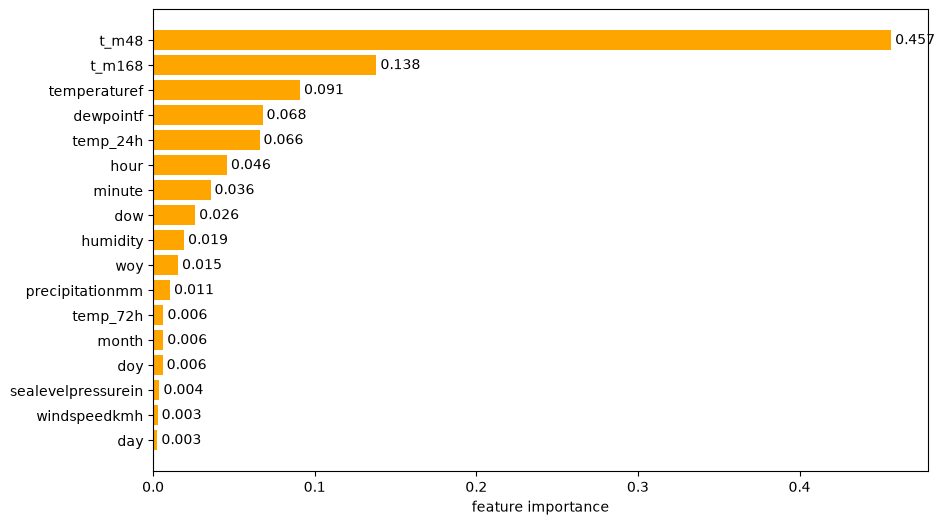

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(fi.index, fi.values, color='orange')
for i, v in enumerate(fi.values):
    ax.text(v, i, ' ' + str(round(v, 3)), va='center')   # 在每根柱子末端标上数值
ax.set_xlabel('feature importance')
# ax.barh(名字, 数值) 画横向柱子，一个特征一根。因为前面从小到大排过序，最重要的会在最上面。
# enumerate(fi.values) 依次给出序号 i 和数值 v；ax.text(v, i, 文字) 在横坐标 v、第 i 根柱子的位置写上数值，va='center' 让文字和柱子垂直居中对齐。

这里的重要性是「增益」：XGBoost 默认统计的是每个特征在分裂时让误差下降了多少，再归一化。它反映的是模型用了谁，不是去掉它会差多少。
相关的特征会互相分走重要性。 hour 和 minute、doy 和 woy 和 month、temperaturef 和 temp_24h 都是这种关系，所以单看某一个偏低，不代表这类信息不重要。

保存2025年预测结果，用来在下一个notebook和NYISO对比

In [20]:
pred_2025 = full_captial.loc[~train_mask, ['timestamp', 'load', 'temperaturef', 't_m48']].copy()
pred_2025['prediction'] = best_model.predict(X_test)
pred_2025.to_csv('pred_captial_2025.csv', index=False)

### 4. 总结

#### (1) 这个 notebook 做了什么

用 Capital 区 2021–2024 年的数据训练 XGBoost，预测 2025 年全年的负荷。

1. **数据**：`capital.csv`（5 分钟一条的负荷）和 `kalb_all.csv`（约每小时一条的天气），清洗后共 535027 行。
2. **清洗**：去掉气象要素缺失和时间重复的天气记录，去掉负荷为空的 5 行和夏令时回拨造成的 60 个重复时间戳。
3. **对齐**：用最近邻给每条负荷找时间上最近的一条天气记录，合并成一张表。
4. **特征**：共 17 个。6 个天气量、7 个时间量、2 个历史负荷（`t_m48`、`t_m168`）、2 个平均气温（`temp_24h`、`temp_72h`）。
5. **切分**：按时间切，2021–2024 年训练（427679 行），2025 年测试（107348 行）。
6. **调参**：只在训练集上用 `TimeSeriesSplit` 做 3 折交叉验证，每一折正好是用前面的年份预测下一整年。

和 2024 小数据集的探索相比，有四处不同：

- **去掉了 `t_m24`**：NYISO 的预测是前一天发布的，那时还拿不到 24 小时前的负荷，用了就不公平。
- **滞后特征找不到时留空值**：不再回退取当前时刻的负荷（那样等于把答案当特征），空值交给 XGBoost 处理。`t_m48` 有 1219 行为空，`t_m168` 有 4133 行为空。
- **加回了 `doy`、`woy`、`month`**：训练集有四年，每个季节都见过。
- **只用 XGBoost**：小数据集上它和 GBR 效果相近，但训练快得多。

#### (2) 结果

选出的参数是 `learning_rate=0.05`、`max_depth=4`、`min_child_weight=50`（300 棵树），交叉验证的平均 RMSE 是 84.8，三折分别为 81.1、90.2、83.1。

| 模型 | 训练集 RMSE | 测试集 RMSE | 测试集 MAE | 测试集 R² | 测试集 MAPE |
|---|---|---|---|---|---|
| XGBoost（调参） | 61.2 | **95.2** | 68.9 | 0.874 | 5.74% |
| 朴素（`t_m48`） | 160.9 | 191.5 | 137.0 | 0.492 | 10.79% |

RMSE 和 MAE 的单位是兆瓦，指标是在全部 5 分钟数据上算的。

#### (3) 结论

- **模型有效。** 测试集 RMSE 比朴素 baseline 低一半，MAPE 从 10.8% 降到 5.7%。
- **新加的三个特征有用。** 加入 `t_m168`、`temp_24h`、`temp_72h` 之前，测试集 RMSE 是 103.7、MAPE 是 6.41%，加入后明显下降。
- **历史负荷是最重要的特征。** 按特征重要性，`t_m48` 约占 0.46，`t_m168` 约占 0.14，其次是气温、露点和 `temp_24h`；`day`、`doy`、`month`、风速、气压几乎没有贡献。
- **训练集和测试集的差距不是靠正则化能消除的。** 另行试验过：减小树深、减少树的数量、加大 `min_child_weight`、对行和列抽样，测试误差都几乎不变，把模型变弱反而两边都变差。
- **差距的主要来源是「预测没见过的年份」本身。** 交叉验证里预测下一年的 RMSE 是 81–90，和测试集的 95 在同一水平；训练集里相邻的 5 分钟数据几乎相同，训练误差天然偏低，不适合当参照。
- **2025 年比前几年更难预测。** 2025 年负荷的标准差是 269，前四年是 212–248；朴素 baseline 在 2025 年也从 161 变差到 191.5。

#### (4) 读这些数字时要注意的地方

- **参数的选择接近打平。** `learning_rate=0.1`、`min_child_weight=1` 这一组的交叉验证 RMSE 是 85.1，只差 0.3，它在测试集上的 RMSE 是 92.3。差距在各折的波动范围之内，不能据此说哪组更好，也不能按测试集的结果回头挑参数。
- **用的是实测气温。** NYISO 做预测时只能用天气预报，所以后面即使比它好，也带着这个优势。
- **这里的指标还不能和 NYISO 直接比。** NYISO 的预测是逐小时的，对比时要只取整点的行重新计算。
- **测试集只代表 2025 年、Capital 一个区域。** 换一年或换一个区域，数字会不同。

#### (5) 下一步

取 2025 年整点的预测，和 `forecast_2025.csv` 里 `zone == 'CAPITL'` 的官方预测按时间合并，在同一批行上比较两边的 MAPE、RMSE、MAE、R²。